calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object m

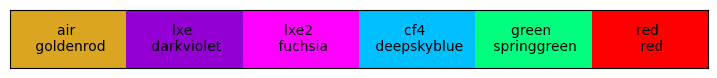

In [1]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang
import time

import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEModel.OpticsDataLoader import *
import PDEModel.MathEquations as ME
import PDEModel.PhotonInfo as PI
# from PDEModel.PNJunction import *
import PDEModel.PNJunction as PNJ

import FittingTools.PDE_fittingTools as SS
from FittingTools import FittingFunctions as FF

from scipy.interpolate import interp1d

import PDEModel.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

Vc = 1.734 ± 0.078


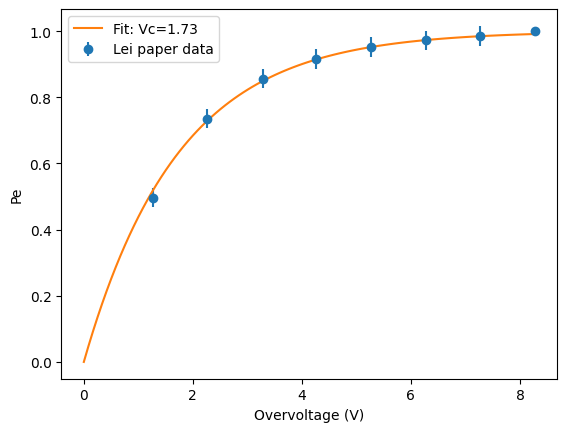

In [2]:
## Load and fit Pe data from Lei paper
import PDEModel.MathEquations as ME
from iminuit import Minuit

xV_pe, yV_pe = np.loadtxt(os.path.join(VERA_DATA_PATH, "PE_vsV", "Pe_fbk_m60C_leiPaper.csv"), delimiter=",", skiprows=1, unpack=True)
yErr_pe = 0.03 * np.ones_like(yV_pe)  # 3% error on all points
yErr_pe[-1] = 0.01  # 3% error, 0.1% on highest V
# yErr_pe = 1.0

chisq = lambda Vc: np.sum(((ME.Pcar_parametrized(xV_pe, Vc, 1.0) - yV_pe) / yErr_pe)**2)
m = Minuit(chisq, Vc=1.9); m.migrad()
print(f"Vc = {m.values['Vc']:.3f} ± {m.errors['Vc']:.3f}")

plt.errorbar(xV_pe, yV_pe, yerr=yErr_pe, fmt='o', label='Lei paper data')
# plt.plot(xV_pe, yV_pe, 'o', label='Lei paper data') # --- IGNORE ---
xfit = np.linspace(0, max(xV_pe), 100)
plt.plot(xfit, ME.Pcar_parametrized(xfit, m.values['Vc'], 1.0), '-', label=f"Fit: Vc={m.values['Vc']:.2f}")
plt.xlabel("Overvoltage (V)"); plt.ylabel("Pe"); plt.legend(); plt.show()

---
### Loading low res data

In [3]:
print("---- Low Res Data ----")
file_path = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_LowRes_stat_error_only_April18.csv")
# file_path = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_LowRes_stat_error_only_June2024.csv") # 1V data is higher in this dataset?
df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
print("Voltages:", df['Overvoltage'].unique())
print("Angles:", df['Angle'].unique())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

---- Low Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE      PDE_error
387     790.012      0            8  2.830000e-13  0.075662  6.918510e-310
388     799.979      0            8  2.470000e-13  0.066172  6.918510e-310
389     809.978      0            8  2.220000e-13  0.059495  6.918510e-310
390     820.008      0            8  2.220000e-13  0.059251  6.918510e-310
391     830.012      0            8  2.140000e-13  0.057313  6.918510e-310
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64
Voltages: [1 2 3 4 5 6 7 8]
Angles: [0]


In [4]:
print("---- High Res Data ----")

# file_pathHR = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_HR_2_may6.csv") # this dataset has a nuisance fit that does not converge
file_pathHR = os.path.join(VERA_DATA_PATH, "FBK_IR_PDE_HR_may6.csv")
dfHR = pd.read_csv(file_pathHR, header=0)
print(dfHR.tail())


data_anglesHR = dfHR['Angle'].unique()
data_voltagesHR = dfHR['Overvoltage'].unique()

print("voltages:", data_voltagesHR)
print("angles:", data_anglesHR)
print("wlen range:", dfHR['Wavelength'].min(), dfHR['Wavelength'].max())

---- High Res Data ----
     Wavelength  Angle  Overvoltage  Responsivity       PDE  PDE_error
395     488.010      0            8  1.317970e-12  0.346423   0.000507
396     490.961      0            8  1.259270e-12  0.330992   0.007925
397     493.970      0            8  1.237670e-12  0.325315   0.009137
398     496.980      0            8  1.218070e-12  0.320163   0.012406
399     499.990      0            8  1.180930e-12  0.310400   0.005496
voltages: [1 2 3 4 5 6 7 8]
angles: [0]
wlen range: 349.97 499.99


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
difference: 1.4494263220723724


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


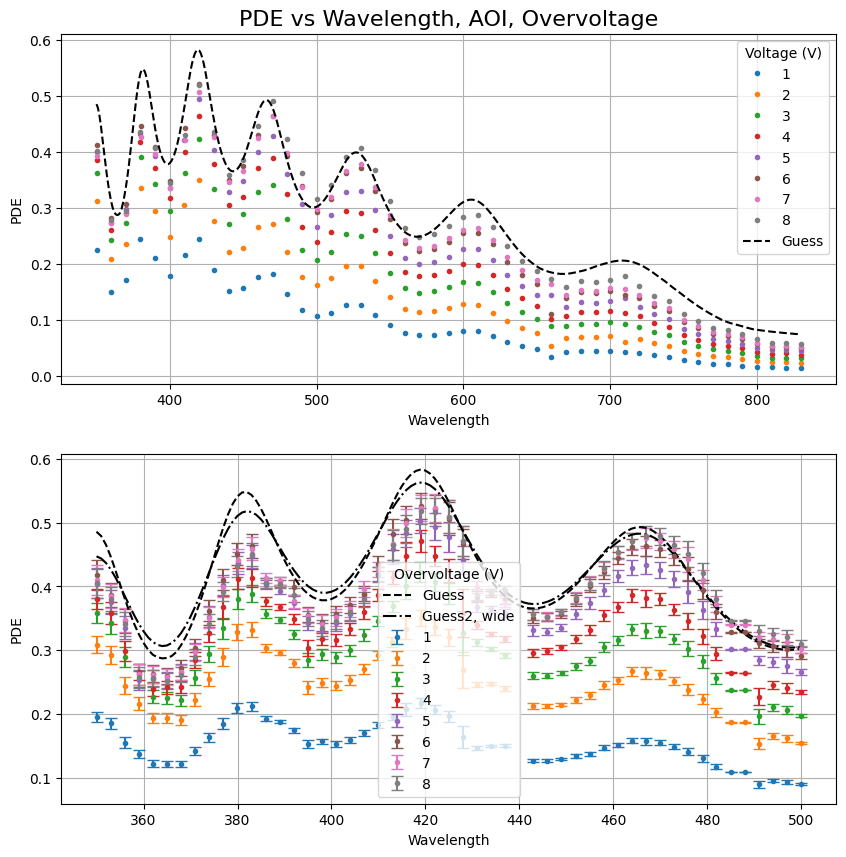

Angles: [1 2 3 4 5 6 7 8]
voltages: [1 2 3 4 5 6 7 8]


In [5]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=False, figsize = (10, 10))

for voltage in data_voltages:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax1)

# xv4 = df[df['Overvoltage'] == 4]
for voltage in data_voltagesHR:
    dt1 = dfHR[(dfHR['Angle'] == 0) & (dfHR['Overvoltage'] == voltage)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)
    

# some guesses
xGuess = np.arange(df['Wavelength'].min(), df['Wavelength'].max(), 1)
test_Boring = {"FF": 0.8, "quantum": False, "smoothSigma": None, "dh":None}

test_Boring2 = {"FF": 0.8, "quantum": False, "smoothSigma": 10, "dh":None}

testPars = {"tOxide": 1358, "dp_star": 1, "Xpn": 0.3e3, "dw_star": 6e3, "pe": 0.95, "ph": 0.35}
yGuess = FF.PDE_allArgs_wlen(wlen=xGuess, theta1=0, **testPars, **test_Boring)
ax1.plot(xGuess, yGuess, label = "Guess", color = "black", linestyle = "--")

xGuess2 = np.arange(dfHR['Wavelength'].min(), dfHR['Wavelength'].max(), 1)
yGuess2 = FF.PDE_allArgs_wlen(wlen=xGuess2, theta1=0, **testPars, **test_Boring)
ax2.plot(xGuess2, yGuess2, label = "Guess", color = "black", linestyle = "--")


yGuess_3 = FF.PDE_allArgs_wlen(wlen=xGuess2, theta1=0, **testPars, **test_Boring2)
ax2.plot(xGuess2, yGuess_3, label = "Guess2, wide", color = "black", linestyle = "-.")

print("difference:", np.sum(np.abs(yGuess2 - yGuess_3)))

ax1.legend(title = "Voltage (V)")
ax1.set_ylabel("PDE")

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

ax1.grid(), ax2.grid()
# ax2.set_xlim(380, 420)

ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
# plt.subplots_adjust(hspace=0)
plt.show()
print("Angles:", data_voltages)
print("voltages:", data_voltages)

---
## Physics and Global Parameters
### input systematics

In [6]:
# these are bad
dh_franta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dh_frantaRT = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))

MCFWHM = 4.5 # nm/mm

class systematics:
    def __init__(self):
        return

sys1 = systematics()

sys1.mScale = 1.32
sys1.mc_fwhm = MCFWHM * sys1.mScale # in nm
sys1.diodeError = 0.03
sys1.dh = dh_franta
sys1.temp = None
sys1.FF1 = 0.8
sys1.vOffset = 0.075 # this is subtracted

sys1.uvLim = 400

sys1.tOxide = 1358.9

peOutFileName = "FBK_Pcurves_global_FRANTA_nested_mar2_2026.csv"

## bounds and fixed (boring) parameters
fixedPars_UV_parametrized = {"tOxide": sys1.tOxide,
                             "case": "B", 
                             "Temperature": sys1.temp, "quantum": True, "smoothSigma": sys1.mc_fwhm, "dh":sys1.dh,
                             "FF": sys1.FF1, "window": False}

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt


{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}
---- Harry Pe values ----


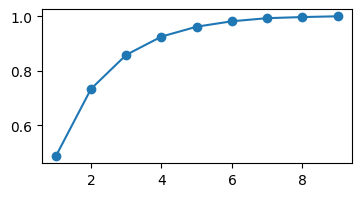

In [7]:
## Loading in Harry's PE data
file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}
print(harryPedict)
fHarry_interpPe = interp1d(df_pe["Overvoltage"], harryPe, kind='linear', fill_value="extrapolate")

print("---- Harry Pe values ----")
plt.figure(figsize=(4, 2))
plt.plot(df_pe["Overvoltage"], harryPe, marker = "o")
plt.show()

[0.0090828  0.00982663 0.00777457 0.01433748 0.00615109 0.00929369
 0.0157151  0.01434825]
0.006151085970945968


array([0.10050373, 0.10777755, 0.13483694, 0.18935681, 0.27041635,
       0.37536116, 0.50249478, 0.65091935, 0.82015913])

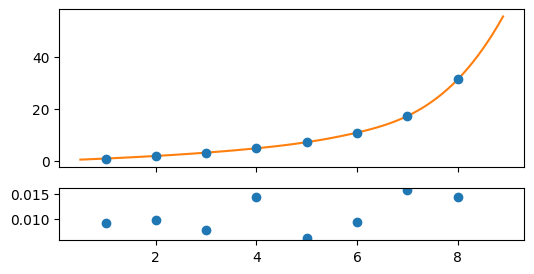

In [8]:
## loading in Harry's NCA error data 
file_path_nca = os.path.join(VERA_DATA_PATH, "NCA_errors/FBK_Q_sept24.csv")

xV_nca, yV_nca, yE_nca = np.loadtxt(file_path_nca, delimiter=",", unpack=True, skiprows=1, usecols=(0, 1, 2))

yV_nca_relative = yV_nca/min(yV_nca)
yE_nca_relative = yE_nca/yV_nca
print(yE_nca_relative)
finterp_nca = interp1d(xV_nca, yV_nca_relative, kind = "cubic", fill_value = "extrapolate")
finterp_ncaError = interp1d(xV_nca, yE_nca_relative, kind = "cubic", fill_value = "extrapolate")


fig, (ax1, ax2) = plt.subplots(2, 1, sharex=1, figsize = (6, 3), height_ratios=[3, 1])
ax1.errorbar(xV_nca, yV_nca_relative, yerr=10*yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
xfurther = np.arange(0.5, 9, 0.1)
ax1.plot(xfurther, finterp_nca(xfurther), label = "Interpolated")

ax2.plot(xV_nca, yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
# ax2.plot(xfurther, finterp_ncaError(xfurther), label = "Interpolated")

def getClosestNCAError(voltage):
    amin = np.argmin(np.abs(xV_nca - voltage))
    return yE_nca_relative[amin]

print(getClosestNCAError(4.6))

def quadErrors(value, valueErrors, *constantRelErrors):
    creArray = np.array(constantRelErrors)
    return value * np.sqrt((valueErrors/value)**2 + np.sum((creArray)**2))

xt = np.arange(0.1, 1, 0.1)
yt = xt**2
yerr = 0.1*yt

quadErrors(yt, yerr/yt, 1.0, 0.1)


---
## Building dataset object(s)

building 1d and 2d objects for single and nested fits

In [9]:
##-- Buiding global dataset from HR and LR data --##
angle_0A = data_angles[0]
print("picking angle:", angle_0A)

voltageTracker = data_voltages[:-2]
print("data voltages:", voltageTracker)

data_global_parametrized = []
data_global_nested = []

dataNested_UV = []
dataNested_IR = []

onlyData_global_LR = []
onlyData_global_HR = []

vHigh = max(voltageTracker)
data_UV_high = []
data_UV_all = []

for V in voltageTracker:
    
    # low res data
    dfA_t1 = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    pde_lr = dfA_t1['PDE']
    pdeErrors_lr = dfA_t1['PDE_error']
    
    vToAnalyze = V - sys1.vOffset
    
    # total error on each PDE value
    totalPDEerror_lr = quadErrors(pde_lr, pdeErrors_lr, sys1.diodeError, getClosestNCAError(V))
    
    oneD_LRdict = {"wlen":dfA_t1['Wavelength'].values, "yVals": pde_lr, "yErrs": totalPDEerror_lr,
                   "theta1": angle_0A, "voltage": vToAnalyze}
    onlyData_global_LR.append(oneD_LRdict)
    data_global_parametrized.append(oneD_LRdict)
    
    # high res data
    dft1_HR = dfHR[(dfHR['Overvoltage'] == V) & (dfHR['Angle'] == angle_0A)]
    pde_hr = dft1_HR['PDE']
    pdeErrors_hr = dft1_HR['PDE_error']
    totalPDEerror_hr = quadErrors(pde_hr, pdeErrors_hr, sys1.diodeError, getClosestNCAError(V))
    
    oneD_HRdict = {"wlen":dft1_HR['Wavelength'].values, "yVals": pde_hr, "yErrs": totalPDEerror_hr, "theta1": angle_0A, "voltage": vToAnalyze}
    onlyData_global_HR.append(oneD_HRdict)
    data_global_parametrized.append(oneD_HRdict)
    
    #### UV and voltage datasets
    # print(dft1_HR['Wavelength'].values)
    uvMap_below400_hr = dft1_HR['Wavelength'].values < sys1.uvLim
    uvMap_below400_lr = dfA_t1['Wavelength'].values < sys1.uvLim
    
    oneD_lr_UV = {"wlen":dfA_t1['Wavelength'].values[uvMap_below400_lr], "yVals": pde_lr[uvMap_below400_lr], "yErrs": totalPDEerror_lr[uvMap_below400_lr], "theta1": angle_0A, "voltage": vToAnalyze}
    oneD_hr_UV = {"wlen":dft1_HR['Wavelength'].values[uvMap_below400_hr], "yVals": pde_hr[uvMap_below400_hr], "yErrs": totalPDEerror_hr[uvMap_below400_hr], "theta1": angle_0A, "voltage": vToAnalyze}
    data_UV_all.append(oneD_lr_UV)
    data_UV_all.append(oneD_hr_UV)
    if V == vHigh:
        tlr = oneD_lr_UV.copy()
        tlr.pop("voltage")
        thr = oneD_hr_UV.copy()
        thr.pop("voltage")
        data_UV_high.append(tlr)
        data_UV_high.append(thr)
    
    ############ for nested Pe, Ph fits ##############
    ## MUST REMOVE VOLTAGES FROM HERE
    odLR_copy = oneD_LRdict.copy()
    odHR_copy = oneD_HRdict.copy()
    odLR_copy.pop("voltage")
    odHR_copy.pop("voltage")
    dataDict_array = [odLR_copy, odHR_copy]
    # print(dataDict_array[0].keys())
    
    tempFixedPE = fHarry_interpPe(vToAnalyze)
    # print("V:", V, "guess pe:", tempFixedPE)
    
    floatNuisDict = {"pe": tempFixedPE, "ph": 0.15}
    floatBoundsNuisDict = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    odFullS = SS.OneNuisanceDataSet(oneDData=dataDict_array, nuisanceFloat=floatNuisDict, nuisanceBounds=floatBoundsNuisDict, nuisanceFixed={})
    # ndof stuff
    ndof = odFullS.CalcNDOF(xkey="wlen")
    # print("NDOF:", ndof)
    
    odFullS.extraV = vToAnalyze
    data_global_nested.append(odFullS)

# type(data_global_nested[0].oneDData);

# for single layer fits
SS.CheckDataSetKey_consistent(data_global_parametrized, True);
type(data_global_parametrized[0])
print(data_global_parametrized[0].keys())

picking angle: 0
data voltages: [1 2 3 4 5 6]
-- CheckDataSetKey_consistent() --
	Dataset(s) have same keys, proceed
dict_keys(['wlen', 'yVals', 'yErrs', 'theta1', 'voltage'])


---
### UV fit high voltage


In [10]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_A_UV = {**fixedPars_UV_parametrized, "Xpn": 2e3, "dw_star":10e3, "ph":0.0,  'pe':1.0}

floatPars_A_UV = {"dp_star": 1.5}
floatBounds_A_UV = {"dp_star": (0.01, 14)}

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen, dataObj=data_UV_high, dFixed=fixedPars_A_UV, dFloat=floatPars_A_UV,
                                   dBounds=floatBounds_A_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_A_UV, functionToFit=FF.PDE_allArgs_wlen)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case AE-UV Fit ------")
result_A_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_A_UV, data_UV_high, FF.PDE_allArgs_wlen), method='migrad')
SS.GenericResiduals(x0=result_A_UV.x, dataObj=data_UV_high, functionToFit=FF.PDE_allArgs_wlen, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_A_UV)
print("chi2 score-ish:", result_A_UV.fun)

resDict_A_UV = SS.GetResDict(result_A_UV, xoAE_UV_Names)
resDictErrors_A_UV = SS.GetResErrorDict(result_A_UV, xoAE_UV_Names)
print(resDict_A_UV)
print("errors:", resDictErrors_A_UV)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 335.49989852370163
{'dp_star': 3.2125}
errors: {'dp_star': 0.1152}
chi2 score-ish: 335.49989852370163
{'dp_star': 3.2125}
errors: {'dp_star': 0.1152}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:791: ComplexWarning: Casting complex values to real discards the imaginary part
  fm = migrad(ncall, self._tolerance)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


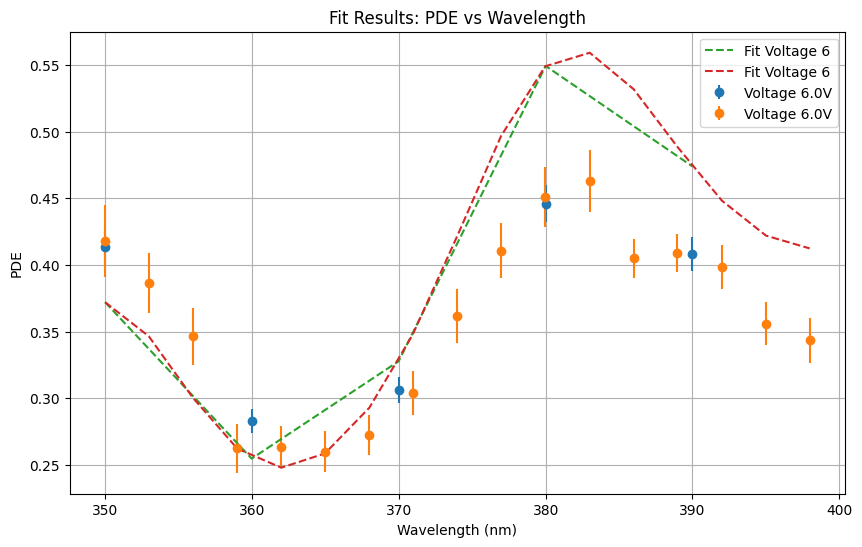

In [11]:
# Plotting the result of the fit
plt.figure(figsize=(10, 6))

# Plot the data points with error bars
for dat in data_UV_high:
    xVals = dat["wlen"]
    yVals = dat["yVals"]
    yErrs = dat["yErrs"]
    plt.errorbar(xVals, yVals, yerr=yErrs, fmt='o', label=f"Voltage {vHigh:.1f}V")

# Plot the fitted curve
for dat in data_UV_high:
    xVals = dat["wlen"]
    if len(xVals) < 5:
        continue
    voltage = vHigh
    yFit = FF.PDE_allArgs_wlen(wlen=xVals, theta1=angle_0A, **resDict_A_UV, **fixedPars_A_UV)
    plt.plot(xVals, yFit, linestyle='--', label=f"Fit Voltage {voltage}")

plt.xlabel("Wavelength (nm)")
plt.ylabel("PDE")
plt.title("Fit Results: PDE vs Wavelength")
plt.legend()
plt.grid()
plt.show()

---
### UV all voltages

In [12]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_B_UV = {**fixedPars_UV_parametrized, "Xpn": 2e3, "dw_star":10e3, "Ah": 0.0, "Ae":1.0, "Vh":100}

floatPars_B_UV = {"dp_star": 1.5, 'Ve':2.0}
floatBounds_B_UV = {"dp_star": (0.01, 14), 'Ve': (0.0, 10)}

print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_UV_all, dFixed=fixedPars_B_UV, dFloat=floatPars_B_UV,
                                   dBounds=floatBounds_B_UV, yNames=("yVals", "yErrs"), verbose=False)
xoB_UV, xoB_UV_Names = SS.BuildX0(floatDict=floatPars_B_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_B_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case AE-UV Fit ------")
result_B_UV = iminuit.minimize(SS.GenericResiduals, x0=xoB_UV, bounds = xABounds, args=(fixedPars_B_UV, data_UV_all, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_B_UV.x, dataObj=data_UV_all, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_B_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_B_UV)
ndof = np.sum([len(dat['wlen']) for dat in data_UV_all]) - len(xoB_UV)
print("NDOF:", ndof)

print("reduced chi2 score-ish:", result_B_UV.fun/ndof)

resDict_B_UV = SS.GetResDict(result_B_UV, xoB_UV_Names)
resDictErrors_B_UV = SS.GetResErrorDict(result_B_UV, xoB_UV_Names)
print(resDict_B_UV)
print("errors:", resDictErrors_B_UV)


List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
------ Case AE-UV setup ------
------ Case AE-UV Fit ------
NDOF: 131
reduced chi2 score-ish: 8.431688857131054
{'dp_star': 1.238, 'Ve': 2.1288}
errors: {'dp_star': 0.0584, 'Ve': 0.0168}
NDOF: 131
reduced chi2 score-ish: 8.431688857131054
{'dp_star': 1.238, 'Ve': 2.1288}
errors: {'dp_star': 0.0584, 'Ve': 0.0168}


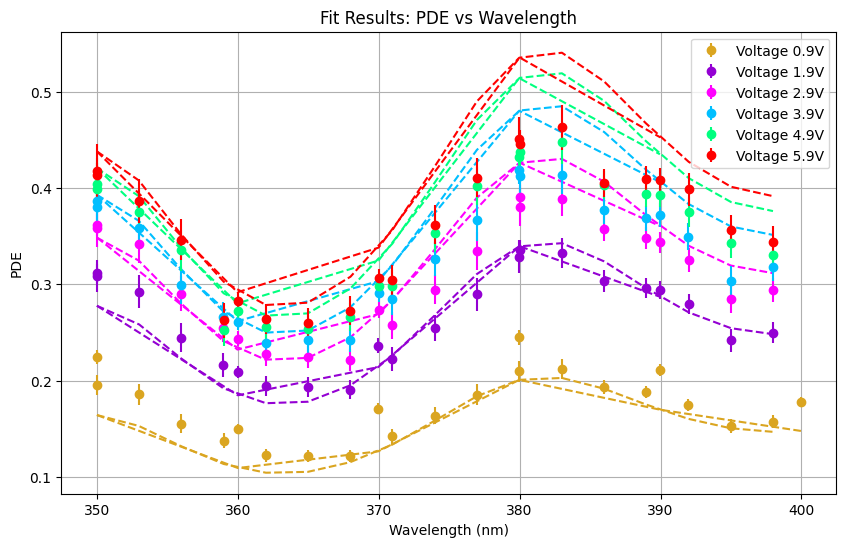

In [13]:
# Plotting the result of the fit
plt.figure(figsize=(10, 6))
i = 0
# Plot the data points with error bars
for dat in data_UV_all:
    xVals = dat["wlen"]
    yVals = dat["yVals"]
    yErrs = dat["yErrs"]
    if i % 2 == 0:
        col = ms.GetNextColor()
    i += 1
    volt = dat["voltage"]
    
    lab = "" if i % 2 == 0 else f"Voltage {volt:.1f}V"
    plt.errorbar(xVals, yVals, yerr=yErrs, fmt='o', label=lab, color = col)
    
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=xVals, voltage = volt, theta1=angle_0A, **resDict_B_UV, **fixedPars_B_UV)
    plt.plot(xVals, yFit, linestyle='--', color = col)


plt.xlabel("Wavelength (nm)")
plt.ylabel("PDE")
plt.title("Fit Results: PDE vs Wavelength")
plt.legend()
plt.grid()
plt.show()

---
### full Sequential Fit




In [14]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_IR =  {**fixedPars_UV_parametrized, **resDict_B_UV, "Ah": 1.0, "Ae":1.0}
print(fixedPars_IR)

floatPars_IR = {"Xpn": 0.5e3, "dw_star":5e3, "Vh":15}
floatBounds_IR = {"Xpn": (0.0, 3e3), "dw_star":(3, 15e3), "Vh":(0.0, 30)}

print("------ Case A IR setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_global_parametrized, dFixed=fixedPars_IR, dFloat=floatPars_IR,
                                   dBounds=floatBounds_IR, yNames=("yVals", "yErrs"), verbose=False)
xo_A_IR, xo_A_IR_Names = SS.BuildX0(floatDict=floatPars_IR, functionToFit=FF.PDE_allArgs_wlen_parametrized)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_IR, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case A IR Fit ------")
result_IR = iminuit.minimize(SS.GenericResiduals, x0=xo_A_IR, bounds = xABounds, args=(fixedPars_IR, data_global_parametrized, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_IR.x, dataObj=data_global_parametrized, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_IR, verbose=False, yNames=("yVals", "yErrs"))

# print(result_IR)
ndof = np.sum([len(dat['wlen']) for dat in data_global_parametrized]) - len(xo_A_IR)
print("NDOF:", ndof)

print("reduced chi2 score-ish:", result_IR.fun/ndof)

resDict_IR = SS.GetResDict(result_IR, xo_A_IR_Names)
resDictErrors_IR = SS.GetResErrorDict(result_IR, xo_A_IR_Names)
print(resDict_IR)
print("errors:", resDictErrors_IR)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
{'tOxide': 1358.9, 'case': 'B', 'Temperature': None, 'quantum': True, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1524bb5d0>, 'FF': 0.8, 'window': False, 'dp_star': 1.238, 'Ve': 2.1288, 'Ah': 1.0, 'Ae': 1.0}
------ Case A IR setup ------
------ Case A IR Fit ------
NDOF: 591
reduced chi2 score-ish: 6.471106063867897
{'Xpn': 770.5829, 'dw_star': 4925.9261, 'Vh': 15.076}
errors: {'Xpn': 7.7768, 'dw_star': 83.2125, 'Vh': 0.3684}
NDOF: 591
reduced chi2 score-ish: 6.471106063867897
{'Xpn': 770.5829, 'dw_star': 4925.9261, 'Vh': 15.076}
errors: {'Xpn': 7.7768, 'dw_star': 83.2125, 'Vh': 0.3684}


In [15]:
# Printing results and errors for the three sequential fits along with chi2 scores
print("UV limit:", sys1.uvLim)
print("UV high V Fit:")
print("Results:", resDict_A_UV)
print("Errors:", resDictErrors_A_UV)
print("Chi2:", result_A_UV.fun)

print("\nUV all V Fit:")
print("Results:", resDict_B_UV)
print("Errors:", resDictErrors_B_UV)
print("Chi2:", result_B_UV.fun)

print("\nIR Fit:")
print("Results:", resDict_IR)
print("Errors:", resDictErrors_IR)
print("Chi2:", result_IR.fun)

UV limit: 400
UV high V Fit:
Results: {'dp_star': 3.2125}
Errors: {'dp_star': 0.1152}
Chi2: 335.49989852370163

UV all V Fit:
Results: {'dp_star': 1.238, 'Ve': 2.1288}
Errors: {'dp_star': 0.0584, 'Ve': 0.0168}
Chi2: 1104.551240284168

IR Fit:
Results: {'Xpn': 770.5829, 'dw_star': 4925.9261, 'Vh': 15.076}
Errors: {'Xpn': 7.7768, 'dw_star': 83.2125, 'Vh': 0.3684}
Chi2: 3824.4236837459275


---
### global 1: Single Level - Parametrized fit

no floating Psaturation or anything else like that

------ Case global1 setup ------
check all good: True
{'Ah': 1.0, 'case': 'B', 'Temperature': None, 'quantum': True, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1524bb5d0>, 'FF': 0.8, 'window': False, 'Ae': 1.0}


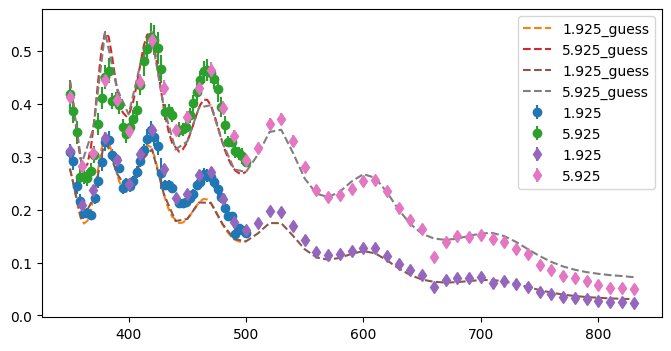

In [16]:
datFit = data_global_parametrized

psatFloat = False

## bounds and fixed (boring) parameters
fixedPars_g1_parametrized = {"Ah":1.0, **fixedPars_UV_parametrized, "Ae":1.0}
  
fixedPars_g1_parametrized.pop("tOxide")

# dh options
# None, dh_franta, dh_frantaRT

floatPars_g1_parametrized =  {"tOxide": 1355, "dp_star": 1.0, "Xpn": 0.5e3, "dw_star": 7e3, "Ve":2.2, "Vh":14}

if psatFloat:
  fixedPars_g1_parametrized.pop("Ae")
  floatPars_g1_parametrized["Ae"] = 1.0

if (fixedPars_g1_parametrized["dh"] is not None) and fixedPars_g1_parametrized["Temperature"] is not None:
    if "franta" in fixedPars_g1_parametrized["dh"].mPathSi or "Franta" in fixedPars_g1_parametrized["dh"].mPathSi:
        print("Using franta and setting temperature. this is wrong. EXITING")
        sys.exit()
    
floatParBounds_global1 = {"Ae":(0.6, 1.1), "tOxide": (1345, 1365), "dp_star": (0.01, 10), "Xpn": (0.2e3, 1.4e3), "dw_star": (2e3, 20e3), "Ve": (0.5, 4), "Vh": (4, 30)}
floatParBounds_global1 = {k: floatParBounds_global1[k] for k in floatPars_g1_parametrized.keys()}

x0_global1, x0_global1_names = SS.BuildX0(floatDict = floatPars_g1_parametrized, functionToFit=FF.PDE_allArgs_wlen_parametrized)
x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized)


print("------ Case global1 setup ------")
check = SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=datFit, dFixed=fixedPars_g1_parametrized, dFloat=floatPars_g1_parametrized,
                                   dBounds=floatParBounds_global1, yNames=("yVals", "yErrs"), verbose=False)
print("check all good:", check)

############
## plot the guess at one high and one low voltage for HR data
plt.figure(figsize=(8, 4))
for d in [onlyData_global_HR[1], onlyData_global_HR[-1]]:
    plt.errorbar(d["wlen"], d["yVals"], yerr=d["yErrs"], label = f"{d['voltage']}", marker = "o", linestyle = "")
    
    yGuess = FF.PDE_allArgs_wlen_parametrized(wlen=d["wlen"], voltage = d['voltage'], theta1=angle_0A , **fixedPars_g1_parametrized, **floatPars_g1_parametrized)
    plt.plot(d["wlen"], yGuess, label = f"{d['voltage']}_guess", linestyle = "--")
    
for d in [onlyData_global_LR[1], onlyData_global_LR[-1]]:
    plt.errorbar(d["wlen"], d["yVals"], yerr=d["yErrs"], label = f"{d['voltage']}", marker = "d", linestyle = "")
    
    yGuess2 = FF.PDE_allArgs_wlen_parametrized(wlen=d["wlen"], voltage = d['voltage'], theta1=angle_0A , **fixedPars_g1_parametrized, **floatPars_g1_parametrized)
    plt.plot(d["wlen"], yGuess2, label = f"{d['voltage']}_guess", linestyle = "--")


print(fixedPars_g1_parametrized)
plt.legend()


In [17]:

print("------ Case global1 fit ------")
starTime = time.time()
result_global1 = iminuit.minimize(SS.GenericResiduals, x0=x0_global1, bounds = x0_global1_bounds, args=(fixedPars_g1_parametrized, datFit, FF.PDE_allArgs_wlen_parametrized), method='migrad',
                                #   tol = 10,
                                  options = {"display": False})

## calling it again
SS.GenericResiduals(x0=result_global1.x, dataObj=datFit, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_g1_parametrized, verbose=False, yNames=("yVals", "yErrs"), )

print("\nDone fit!, time taken:", time.time()-starTime)
print("chi2 score-ish:", result_global1.fun)

resDict_global1 = SS.GetResDict(result_global1, x0_global1_names)
resDictErrors_global1 = SS.GetResErrorDict(result_global1, x0_global1_names)
print("values:", resDict_global1)
print("errors:", resDictErrors_global1)

------ Case global1 fit ------

Done fit!, time taken: 1.925288200378418
chi2 score-ish: 3798.864908257642
values: {'tOxide': 1359.7505, 'dp_star': 1.515, 'Xpn': 711.1878, 'dw_star': 4690.6937, 'Ve': 2.0441, 'Vh': 13.7176}
errors: {'tOxide': 0.2003, 'dp_star': 0.0572, 'Xpn': 13.1404, 'dw_star': 87.7287, 'Ve': 0.0151, 'Vh': 0.4027}

Done fit!, time taken: 1.925288200378418
chi2 score-ish: 3798.864908257642
values: {'tOxide': 1359.7505, 'dp_star': 1.515, 'Xpn': 711.1878, 'dw_star': 4690.6937, 'Ve': 2.0441, 'Vh': 13.7176}
errors: {'tOxide': 0.2003, 'dp_star': 0.0572, 'Xpn': 13.1404, 'dw_star': 87.7287, 'Ve': 0.0151, 'Vh': 0.4027}


In [18]:
print(result_global1)

  message: Optimization terminated successfully.
  success: True
      fun: 3798.864908257642
        x: [ 1.360e+03  1.515e+00  7.112e+02  4.691e+03  2.044e+00
             1.372e+01]
 hess_inv: ┌────┬─────────────────────────────────────────────────────────────┐
           │    │        x0        x1        x2        x3        x4        x5 │
           ├────┼─────────────────────────────────────────────────────────────┤
           │ x0 │    0.0401    0.0008      0.02      0.55   0.02e-3      0.00 │
           │ x1 │    0.0008   0.00327   -0.3767   -1.5396  -0.55e-3   -0.0084 │
           │ x2 │      0.02   -0.3767       173    0.94e3 160.91e-3      4.84 │
           │ x3 │      0.55   -1.5396    0.94e3   7.7e+03 660.92e-3     34.07 │
           │ x4 │   0.02e-3  -0.55e-3 160.91e-3 660.92e-3  0.000228   3.62e-3 │
           │ x5 │      0.00   -0.0084      4.84     34.07   3.62e-3     0.162 │
           └────┴─────────────────────────────────────────────────────────────┘
     nfev: 226


6
NDOF: 588
reduced chi2: 6.460654605880344


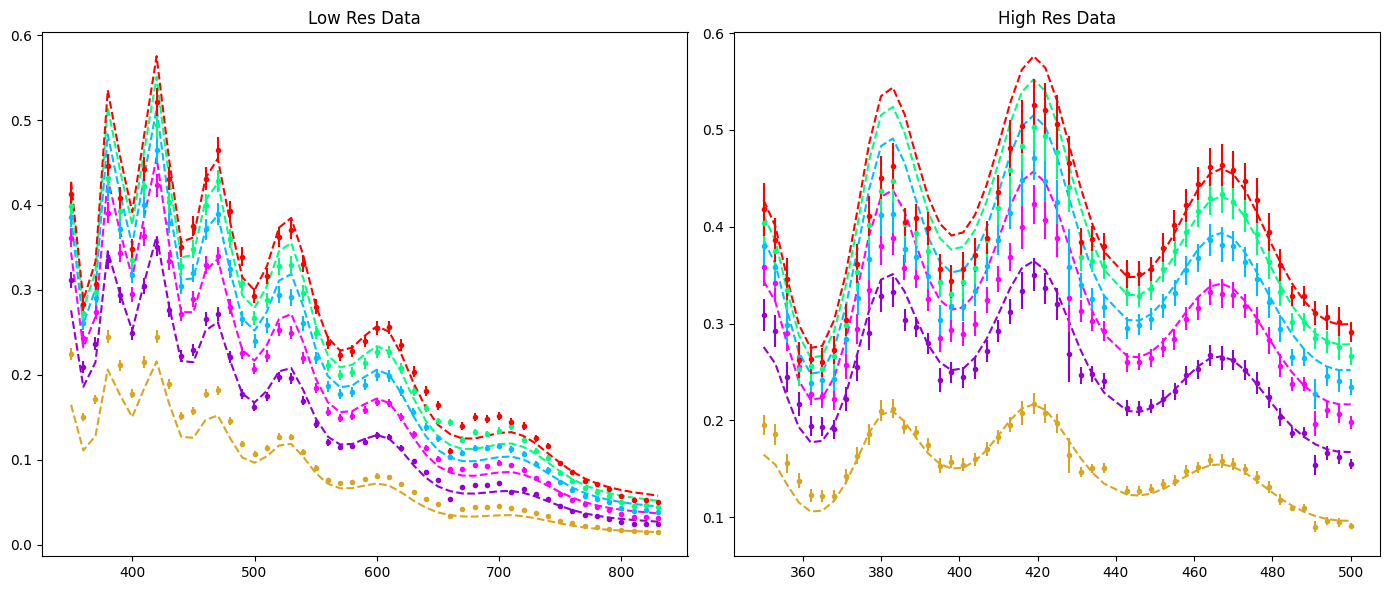

In [19]:

fig, (ax1, ax2) = plt.subplots(1, 2, sharex=False, figsize = (14, 6)) 
ndof = - len(result_global1.x)
print(len(result_global1.x))

for dat in onlyData_global_HR:
    
    col = ms.GetNextColor()
    
    xVals = dat["wlen"]
    v = dat["voltage"]
    yVals = dat["yVals"]
    yErrs = dat["yErrs"]
    ndof += len(xVals)
    
    ax2.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
    
    # yGuess = FF.PDE_allArgs_wlen_parametrized(wlen=xVals, theta1=angle_0A, voltage = v-0.2, **floatPars_g1_parametrized, **fixedPars_g1_parametrized)
    # ax2.plot(xVals, yGuess, color = col, linestyle = "--")
    
    ## fit
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=xVals, theta1=angle_0A, voltage = v, **resDict_global1, **fixedPars_g1_parametrized)
    ax2.plot(xVals, yFit, color = col, linestyle = "--")
    
for dat in onlyData_global_LR:
    
    col = ms.GetNextColor()
    
    xVals = dat["wlen"]
    v = dat["voltage"]
    yVals = dat["yVals"]
    yErrs = dat["yErrs"]
    ndof += len(xVals)

    
    ax1.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
    
    # yGuess = FF.PDE_allArgs_wlen_parametrized(wlen=xVals, theta1=angle_0A, voltage = v, **floatPars_g1_parametrized, **fixedPars_g1_parametrized)
    # ax1.plot(xVals, yGuess, color = col, linestyle = "--")
    
    ## fit
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=xVals, theta1=angle_0A, voltage = v, **resDict_global1, **fixedPars_g1_parametrized)
    ax1.plot(xVals, yFit, color = col, linestyle = "--")

print("NDOF:", ndof)
print("reduced chi2:", result_global1.fun/ndof)

ax1.set_title("Low Res Data")
ax2.set_title("High Res Data" )

plt.tight_layout()

---
## Nested - UV only



In [20]:
data_global_nested_uv = []
dataGlobalNested_IR = []

for d in data_global_nested:
    
    newDataDict_array = []
    for dataDict in d.oneDData:
        xVals = dataDict["wlen"]
        yVals = dataDict["yVals"]
        yErrs = dataDict["yErrs"]
        
        uvMask = xVals < sys1.uvLim
        
        newX = xVals[uvMask]
        newY = yVals[uvMask]
        newYerr = yErrs[uvMask]
        
        dataDict = {"wlen": newX, "yVals": newY, "yErrs": newYerr, "theta1": angle_0A}
        newDataDict_array.append(dataDict)
    
    odFull_uv = SS.OneNuisanceDataSet(oneDData=newDataDict_array, nuisanceFloat={"pe": ME.Pcar_parametrized(d.extraV, Vc=1.8)}, nuisanceBounds={"pe": (0.0, 1.1)}, nuisanceFixed={"ph":0.0})
    odFull_uv.extraV = d.extraV
    data_global_nested_uv.append(odFull_uv)

In [21]:
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_g1_nested_uv = fixedPars_B_UV.copy()
print(fixedPars_g1_nested_uv)
fixedPars_g1_nested_uv.pop("Ah")
fixedPars_g1_nested_uv.pop("Ae")
fixedPars_g1_nested_uv.pop("Vh")

floatPars_g1_nested = {"dp_star":1.0}

floatParBounds_g1_nested = {k: floatParBounds_global1[k] for k in floatPars_g1_nested.keys()}

x0_global_nested_uv, x0_global_nested_uv_Names = SS.BuildX0(floatDict=floatPars_g1_nested, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_uv_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_g1_nested, functionToFit=FF.PDE_allArgs_wlen)

## i forget how to use my check functions lol
# SS.CheckInputs_forResiduals(x0=x0_global_nested_uv, fixedArgs_dict=fixedPars_g1_nested_uv, dataObj = data_global_nested_uv, functionToFit=FF.PDE_allArgs_wlen, yNames = ("yVals", "yErrs"), verbose=False)

print("------ all data, nested fits ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested_uv, globalFixed=fixedPars_g1_nested_uv, dataPackage=data_global_nested_uv,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
{'tOxide': 1358.9, 'case': 'B', 'Temperature': None, 'quantum': True, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1524bb5d0>, 'FF': 0.8, 'window': False, 'Xpn': 2000.0, 'dw_star': 10000.0, 'Ah': 0.0, 'Ae': 1.0, 'Vh': 100}
------ all data, nested fits ------


(294.6805807340402+0j)

In [22]:
st = time.time()
result_globalFit_all_uv = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested_uv, bounds = x0_global_nested_uv_bounds,
                                        args=(fixedPars_g1_nested_uv, data_global_nested_uv, FF.PDE_allArgs_wlen), method='migrad')

print("score:", result_globalFit_all_uv.fun)

SS.GenericResiduals_Nuisance_1(globalFloat=result_globalFit_all_uv.x, globalFixed=fixedPars_g1_nested_uv, dataPackage=data_global_nested_uv,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", int((endTime-st)/60), ":", int((endTime-st)%60))

score: 180.0837680977064
Done fit! Time taken: 0 : 4


In [23]:
# print(result_globalFit_all_uv)
resDict_global_nested_uv = SS.GetResDict(result_globalFit_all_uv, x0_global_nested_uv_Names)
resDictError_global_nested_uv = SS.GetResErrorDict(result_globalFit_all_uv, x0_global_nested_uv_Names)
print("global fit:", resDict_global_nested_uv)
print("global fit errors:", resDictError_global_nested_uv)

peFull_dict_nested = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_nested_uv}

print("pe:", peFull_dict_nested)

# totalDOF = sum([dc.nDOF for dc in data_global_nested_uv]) - len(resDict_global_nested_uv) - len(peFull_dict_nested) - len(phFull_dict_nested)
# reducedChi2 = result_globalFit_all_uv.fun / totalDOF
# print("total DOF:", totalDOF)
# print("Reduced chi2:", reducedChi2)
print("total chi2:", result_globalFit_all_uv.fun)

global fit: {'dp_star': 0.0373}
global fit errors: {'dp_star': 0.0613}
pe: {0.925: (0.3875, 0.0024), 1.925: (0.5809, 0.0037), 2.925: (0.6772, 0.0043), 3.925: (0.7245, 0.0048), 4.925: (0.7652, 0.0049), 5.925: (0.7895, 0.0051)}
total chi2: 180.0837680977064


Voltage: 0.925 pe: 0.3875
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 1.925 pe: 0.5809
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 2.925 pe: 0.6772
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 3.925 pe: 0.7245
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 4.925 pe: 0.7652
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 5.925 pe: 0.7895
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>


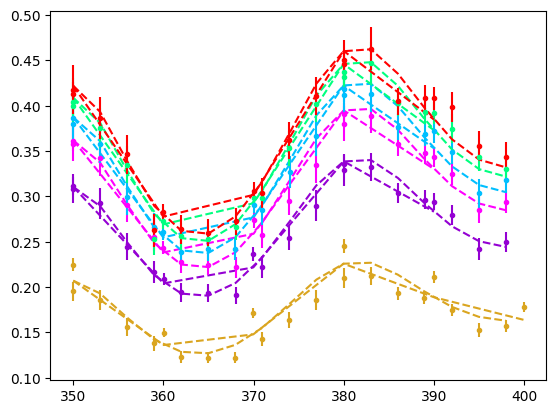

In [24]:
for dc in data_global_nested_uv:
    
    pAv = dc.resultDict
    voltage = dc.extraV
    print("Voltage:", voltage, "pe:", pAv["pe"])
    
    print(type(dc))
    
    col = ms.GetNextColor()
    for oneD in dc.oneDData:
        
        xVals = oneD["wlen"]
        yVals = oneD["yVals"]
        yErrs = oneD["yErrs"]
        
        yFit = FF.PDE_allArgs_wlen(wlen=xVals, theta1=angle_0A, **resDict_global_nested_uv, **fixedPars_g1_nested_uv, **pAv, ph = 0)
        
        plt.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
        plt.plot(xVals, yFit, linestyle = "--", color = col)
        

# plt.xlim(300, 600)
    

---
### Nested - IR sequential

In [25]:
data_global_nested_IR = []

for d, dUV in zip(data_global_nested, data_global_nested_uv):
    
    newDataDict_array = []
    for dataDict in d.oneDData:
        xVals = dataDict["wlen"]
        yVals = dataDict["yVals"]
        yErrs = dataDict["yErrs"]
        
        dataDict = {"wlen": xVals, "yVals": yVals, "yErrs": yErrs, "theta1": angle_0A}
        newDataDict_array.append(dataDict)
    
    correctPe = dUV.resultDict["pe"]
    odFull_uv = SS.OneNuisanceDataSet(oneDData=newDataDict_array, nuisanceFloat={"ph": ME.Pcar_parametrized(d.extraV, Vc=18)}, nuisanceBounds={"ph": (0.0, 1.1)}, nuisanceFixed={"pe": correctPe})
    odFull_uv.extraV = d.extraV
    data_global_nested_IR.append(odFull_uv)

In [26]:
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_g1_nested_IR = {"tOxide": sys1.tOxide, **fixedPars_UV_parametrized, **resDict_global_nested_uv}
print(fixedPars_g1_nested_IR)

floatPars_g1_nested = {"Xpn": 0.5e3, "dw_star":5e3}

floatParBounds_g1_nested = {k: floatParBounds_global1[k] for k in floatPars_g1_nested.keys()}

x0_global_nested_IR, x0_global_nested_IR_Names = SS.BuildX0(floatDict=floatPars_g1_nested, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_IR_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_g1_nested, functionToFit=FF.PDE_allArgs_wlen)

## i forget how to use my check functions lol
# SS.CheckInputs_forResiduals(x0=x0_global_nested_IR, fixedArgs_dict=fixedPars_g1_nested_IR, dataObj = data_global_nested_IR, functionToFit=FF.PDE_allArgs_wlen, yNames = ("yVals", "yErrs"), verbose=False)

print("------ all data, nested fits ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested_IR, globalFixed=fixedPars_g1_nested_IR, dataPackage=data_global_nested_IR,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
{'tOxide': 1358.9, 'case': 'B', 'Temperature': None, 'quantum': True, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1524bb5d0>, 'FF': 0.8, 'window': False, 'dp_star': 0.0373}
------ all data, nested fits ------


(5140.789872334499+0j)

In [27]:
st = time.time()
result_globalFit_all_IR = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested_IR, bounds = x0_global_nested_IR_bounds,
                                        args=(fixedPars_g1_nested_IR, data_global_nested_IR, FF.PDE_allArgs_wlen), method='migrad')

print("score:", result_globalFit_all_IR.fun)

SS.GenericResiduals_Nuisance_1(globalFloat=result_globalFit_all_IR.x, globalFixed=fixedPars_g1_nested_IR, dataPackage=data_global_nested_IR,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", int((endTime-st)/60), ":", int((endTime-st)%60))

score: 2193.2319715468957
Done fit! Time taken: 0 : 9


In [28]:
# print(result_globalFit_all_IR)
resDict_global_nested_IR = SS.GetResDict(result_globalFit_all_IR, x0_global_nested_IR_Names)
resDictError_global_nested_IR = SS.GetResErrorDict(result_globalFit_all_IR, x0_global_nested_IR_Names)
print("global fit:", resDict_global_nested_IR)
print("global fit errors:", resDictError_global_nested_IR)

phFull_dict_nested = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_nested_IR}

print("ph:", phFull_dict_nested)

# totalDOF = sum([dc.nDOF for dc in data_global_nested_IR]) - len(resDict_global_nested_IR) - len(phFull_dict_nested) - len(phFull_dict_nested)
# reducedChi2 = result_globalFit_all_IR.fun / totalDOF
# print("total DOF:", totalDOF)
# print("Reduced chi2:", reducedChi2)
print("total chi2:", result_globalFit_all_IR.fun)

global fit: {'Xpn': 647.2762, 'dw_star': 3397.5127}
global fit errors: {'Xpn': 11.2188, 'dw_star': 43.4902}
ph: {0.925: (0.1104, 0.0009), 1.925: (0.1926, 0.0014), 2.925: (0.2914, 0.0018), 3.925: (0.3812, 0.0023), 4.925: (0.4665, 0.0025), 5.925: (0.5407, 0.0028)}
total chi2: 2193.2319715468957


Voltage: 0.925 ph: 0.1104 pe: 0.3875
Voltage: 1.925 ph: 0.1926 pe: 0.5809
Voltage: 2.925 ph: 0.2914 pe: 0.6772
Voltage: 3.925 ph: 0.3812 pe: 0.7245
Voltage: 4.925 ph: 0.4665 pe: 0.7652
Voltage: 5.925 ph: 0.5407 pe: 0.7895


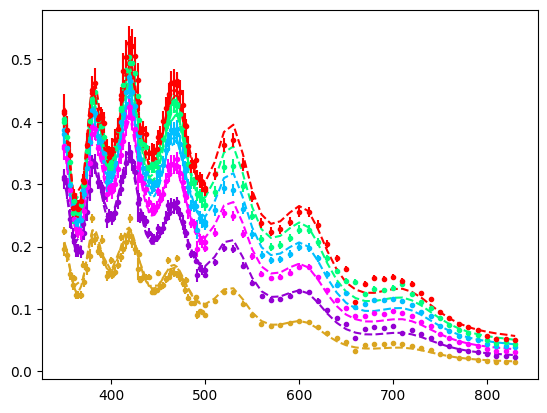

In [29]:
for dc in data_global_nested_IR:
    
    pAv = {**dc.resultDict, **dc.mDict_nuisFixed}
    voltage = dc.extraV
    print("Voltage:", voltage, "ph:", pAv["ph"], "pe:", dc.mDict_nuisFixed["pe"])
    
    # print(type(dc))
    
    col = ms.GetNextColor()
    for oneD in dc.oneDData:
        
        xVals = oneD["wlen"]
        yVals = oneD["yVals"]
        yErrs = oneD["yErrs"]
        
        yFit = FF.PDE_allArgs_wlen(wlen=xVals, theta1=angle_0A, **resDict_global_nested_IR, **fixedPars_g1_nested_IR, **pAv)
        
        plt.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
        plt.plot(xVals, yFit, linestyle = "--", color = col)
        

# plt.xlim(300, 600)
    

---
## Nested Pe, Ph fit (copy the recipe)

In [30]:
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_g1_nested = fixedPars_g1_parametrized.copy()
# fixedPars_g1_nested.pop("Ae")
fixedPars_g1_nested.pop("Ah")

floatPars_g1_nested = floatPars_g1_parametrized.copy()
if "Ae" in floatPars_g1_nested:
    floatPars_g1_nested.pop("Ae")
else:
    fixedPars_g1_nested.pop("Ae")

floatPars_g1_nested.pop("Ve")
floatPars_g1_nested.pop("Vh")

floatParBounds_g1_nested = {k: floatParBounds_global1[k] for k in floatPars_g1_nested.keys()}

x0_global_nested, x0_global_nested_Names = SS.BuildX0(floatDict=floatPars_g1_nested, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_g1_nested, functionToFit=FF.PDE_allArgs_wlen)

## i forget how to use my check functions lol
# SS.CheckInputs_forResiduals(x0=x0_global_nested, fixedArgs_dict=fixedPars_g1_nested, dataObj = data_global_nested, functionToFit=FF.PDE_allArgs_wlen, yNames = ("yVals", "yErrs"), verbose=False)

print("------ all data, nested fits ------")
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested, globalFixed=fixedPars_g1_nested, dataPackage=data_global_nested,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
------ all data, nested fits ------


(6715.311153983038+0j)

In [31]:
st = time.time()
result_globalFit_all = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested, bounds = x0_global_nested_bounds,
                                        args=(fixedPars_g1_nested, data_global_nested, FF.PDE_allArgs_wlen), method='migrad')

print("score:", result_globalFit_all.fun)

SS.GenericResiduals_Nuisance_1(globalFloat=result_globalFit_all.x, globalFixed=fixedPars_g1_nested, dataPackage=data_global_nested,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)
endTime = time.time()
print("Done fit! Time taken:", int((endTime-st)/60), ":", int((endTime-st)%60))

score: 2099.691667152515
Done fit! Time taken: 1 : 11
Done fit! Time taken: 1 : 11


In [32]:
# print(result_globalFit_all)
resDict_global_nested = SS.GetResDict(result_globalFit_all, x0_global_nested_Names)
resDictError_global_nested = SS.GetResErrorDict(result_globalFit_all, x0_global_nested_Names)
print("global fit:", resDict_global_nested)
print("global fit errors:", resDictError_global_nested)

peFull_dict_nested = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_nested}
phFull_dict_nested = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_nested}

print(data_voltages)
print("pe:", peFull_dict_nested)
print("ph:", phFull_dict_nested)

totalDOF = sum([len(dc.oneDData[0]["wlen"]) + len(dc.oneDData[1]["wlen"]) for dc in data_global_nested]) - len(resDict_global_nested) - len(peFull_dict_nested) - len(phFull_dict_nested)
# allXValues = [len(dc.oneDData[0]["wlen"]) for dc in data_global_nested]
# print(allXValues)
reducedChi2 = result_globalFit_all.fun / totalDOF
print("total DOF:", totalDOF)
print("Reduced chi2:", reducedChi2)

peout = np.array(list(peFull_dict_nested.values()))
phout = np.array(list(phFull_dict_nested.values()))

peSave = np.column_stack((list(peFull_dict_nested.keys()), peout)) 
phSave = np.column_stack((list(phFull_dict_nested.keys()), phout))

# np.savetxt("pe_franta_mar2_2k26.csv", peSave, delimiter=",", header="voltage, pe, ph", fmt = "%0.1f, %0.4f, %0.4f")
# np.savetxt("ph_franta_mar2_2k26.csv", phSave, delimiter=",", header="voltage, pe, ph", fmt = "%0.1f, %0.4f, %0.4f")

global fit: {'tOxide': 1359.6745, 'dp_star': 0.2868, 'Xpn': 682.4781, 'dw_star': 3680.3715}
global fit errors: {'tOxide': 0.2099, 'dp_star': 0.0574, 'Xpn': 15.6881, 'dw_star': 60.642}
[1 2 3 4 5 6 7 8]
pe: {0.925: (0.3782, 0.0016), 1.925: (0.5865, 0.0025), 2.925: (0.6906, 0.003), 3.925: (0.7467, 0.0034), 4.925: (0.7947, 0.0036), 5.925: (0.8238, 0.0038)}
ph: {0.925: (0.1021, 0.0011), 1.925: (0.1703, 0.0017), 2.925: (0.2591, 0.0022), 3.925: (0.3396, 0.0027), 4.925: (0.4168, 0.0029), 5.925: (0.4848, 0.0032)}
total DOF: 578
Reduced chi2: 3.632684545246566


In [33]:
ype_global_nested = [peFull_dict_nested[voltage][0] for voltage in peFull_dict_nested.keys()]
ypeErr_global_nested = [peFull_dict_nested[voltage][1] for voltage in peFull_dict_nested.keys()]

yph_global_nested = [phFull_dict_nested[voltage][0] for voltage in phFull_dict_nested.keys()]
yphErr_global_nested = [phFull_dict_nested[voltage][1] for voltage in phFull_dict_nested.keys()]
# Prepare the data to write
data_to_write = {
    "overvoltage": peFull_dict_nested.keys(),
    "pe": ype_global_nested,
    "errpe": ypeErr_global_nested,
    "ph": yph_global_nested,
    "errph": yphErr_global_nested
}

# Convert the data to a DataFrame
df_output = pd.DataFrame(data_to_write)

# Write the DataFrame to a CSV file
df_output.to_csv(peOutFileName, index=False)

print(f"Pe and Ph curves have been written to {peOutFileName}")

Pe and Ph curves have been written to FBK_Pcurves_global_FRANTA_nested_mar2_2026.csv


Voltage: 0.925 pe: 0.3782 ph: 0.1021
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 1.925 pe: 0.5865 ph: 0.1703
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 2.925 pe: 0.6906 ph: 0.2591
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 3.925 pe: 0.7467 ph: 0.3396
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 4.925 pe: 0.7947 ph: 0.4168
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>
Voltage: 5.925 pe: 0.8238 ph: 0.4848
<class 'FittingTools.PDE_fittingTools.OneNuisanceDataSet'>


(300.0, 600.0)

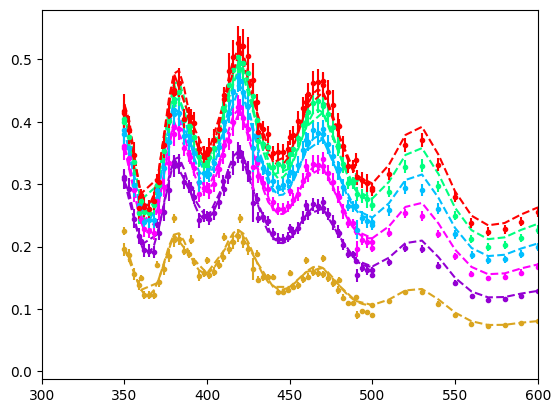

In [34]:
for dc in data_global_nested[::1]:
    
    pAv = dc.resultDict
    voltage = dc.extraV
    print("Voltage:", voltage, "pe:", pAv["pe"], "ph:", pAv["ph"])
    
    print(type(dc))
    
    col = ms.GetNextColor()
    for oneD in dc.oneDData:
        
        xVals = oneD["wlen"]
        yVals = oneD["yVals"]
        yErrs = oneD["yErrs"]
        
        yFit = FF.PDE_allArgs_wlen(wlen=xVals, theta1=angle_0A, **resDict_global_nested, **pAv, **fixedPars_g1_nested)
        
        plt.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
        plt.plot(xVals, yFit, linestyle = "--", color = col)
        

plt.xlim(300, 600)
    

---
### Plotting Pe, Ph curves

[0.925 1.925 2.925 3.925 4.925 5.925]
Fitted parameters: Vc = 2.3019758832214454, A = 1.0


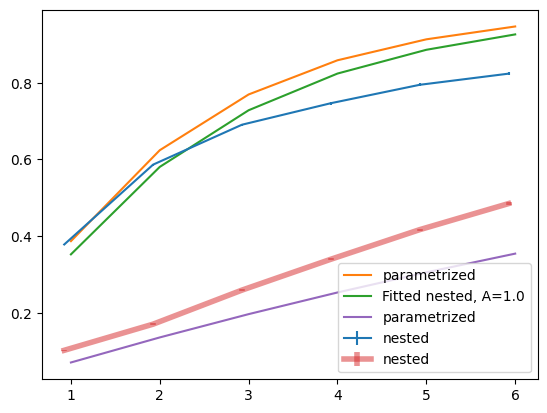

In [35]:
from iminuit import Minuit


xv = np.array(voltageTracker-sys1.vOffset)
print(xv)
ype_nested = np.array([peFull_dict_nested[v] for v in xv])
yph_nested = np.array([phFull_dict_nested[v] for v in xv])

plt.errorbar(xv, ype_nested[:, 0], ype_nested[:, 1], label = "nested")
Aetoplot = resDict_global1["Ae"] if "Ae" in resDict_global1 else 1.0
plt.plot(voltageTracker, ME.Pcar_parametrized(V=voltageTracker, Vc = resDict_global1["Ve"], A = Aetoplot), label = "parametrized")

paData = (xv, ype_nested[:, 0], ype_nested[:, 1])
def p_chi2(A, Vc):
    (xV, y, yerr) = paData
    model = ME.Pcar_parametrized(V=xV, Vc=Vc, A=A)
    return np.sum((y - model)**2/yerr**2)

m = Minuit(p_chi2, A=0.95, Vc=1.5)
m.errordef = Minuit.LEAST_SQUARES
m.fixto("A", 1.0)
m.migrad()

Vc_fit, A_fit = m.values["Vc"], m.values["A"]
print(f"Fitted parameters: Vc = {Vc_fit}, A = {A_fit}")

plt.plot(voltageTracker, ME.Pcar_parametrized(V=voltageTracker, Vc=Vc_fit, A=A_fit), label="Fitted nested, A=1.0")

## holes
plt.errorbar(xv, yph_nested[:, 0], yph_nested[:, 1], linewidth = 4, alpha = 0.5, label = "nested")
plt.plot(voltageTracker, ME.Pcar_parametrized(V=voltageTracker, Vc = resDict_global1["Vh"], A = 1.0), label = "parametrized")

plt.legend()

---
## Plotting Final fit results

-----
fixed inputs for global fit: {'case': 'B', 'Temperature': None, 'quantum': True, 'smoothSigma': 5.94, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x1524bb5d0>, 'FF': 0.8, 'window': False}
-----
global fit, nested: {'tOxide': 1359.6745, 'dp_star': 0.2868, 'Xpn': 682.4781, 'dw_star': 3680.3715}
global fit errors: {'tOxide': 0.2099, 'dp_star': 0.0574, 'Xpn': 15.6881, 'dw_star': 60.642}
total chi2: 2099.691667152515
reduced chi2: 3.632684545246566
max Pe: 0.8238 +/- 0.0038
max Ph: 0.4848 +/- 0.0032
nested dof: 578
----

global fit, param: {'tOxide': 1359.7505, 'dp_star': 1.515, 'Xpn': 711.1878, 'dw_star': 4690.6937, 'Ve': 2.0441, 'Vh': 13.7176}
errors: {'tOxide': 0.2003, 'dp_star': 0.0572, 'Xpn': 13.1404, 'dw_star': 87.7287, 'Ve': 0.0151, 'Vh': 0.4027}
total chi2: 3798.864908257642
reduced chi2: 6.460654605880344
parameterized ndof 588
----


UV all V Fit:
Results: {'dp_star': 1.238, 'Ve': 2.1288}
Errors: {'dp_star': 0.0584, 'Ve': 0.0168}

IR Fit:
Results: {'Xpn': 770.5829,

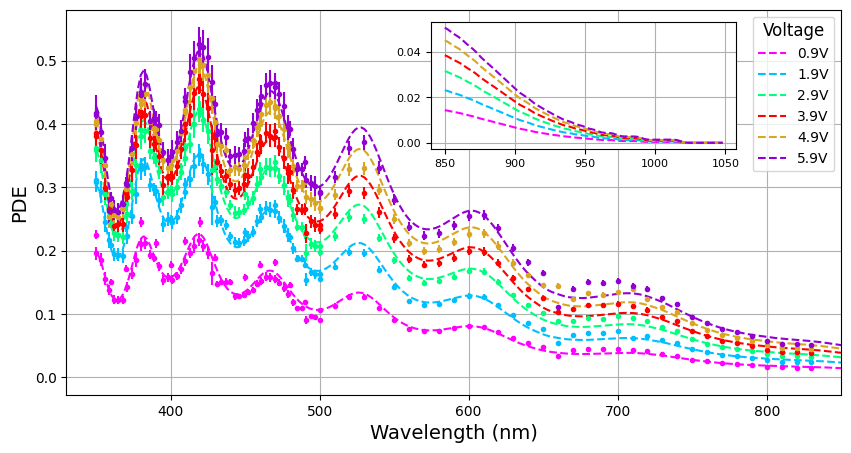

In [36]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


print("-----")
print("fixed inputs for global fit:", fixedPars_g1_nested)
print("-----")
## all fits ##
print("global fit, nested:", resDict_global_nested)
print("global fit errors:", resDictError_global_nested)
print("total chi2:", result_globalFit_all.fun)
print("reduced chi2:", result_globalFit_all.fun/totalDOF)
print("max Pe:", max(ype_global_nested), "+/-", ypeErr_global_nested[-1])
print("max Ph:", max(yph_global_nested), "+/-", yphErr_global_nested[-1])
print("nested dof:", totalDOF)
print("----\n")

print("global fit, param:", resDict_global1)
print("errors:", resDictErrors_global1)
print("total chi2:", result_global1.fun)
print("reduced chi2:", result_global1.fun/ndof)
print("parameterized ndof", ndof)
print("----\n")

# # B is global parametrized fit
# setB_Franta = {"dp_star": 0.63, "Xpn": 654, "dw_star": 3825, "Ve": 1.79, "Vh": 8.5}
# setB_Franta_errors = {"dp_star": 0.06, "Xpn": 14.4, "dw_star": 60, "Ve": 0.013, "Vh": 0.23}

# Printing results and errors for the three sequential fits along with chi2 scores
# print("Results:", resDict_A_UV)
# print("Errors:", resDictErrors_A_UV)

print("\nUV all V Fit:")
print("Results:", resDict_B_UV)
print("Errors:", resDictErrors_B_UV)

print("\nIR Fit:")
print("Results:", resDict_IR)
print("Errors:", resDictErrors_IR)

ms.ResetColorCycle()
ms.GetNextColor()
ms.GetNextColor()
fig, ax1 = plt.subplots(figsize=(10, 5))

spot = (570, 0.35, 205, 0.2) # (x0, y0, width, height) in axes coordinates
axins = inset_axes(ax1, width="100%", height="100%", loc="lower left", bbox_to_anchor=spot, bbox_transform=ax1.transData)

for dc in data_global_nested[::1]:
    
    pAv = dc.resultDict
    voltage = dc.extraV
    print("Voltage:", voltage, "pe:", pAv["pe"], "ph:", pAv["ph"])
    
    # print(type(dc))
    
    col = ms.GetNextColor()
    for oneD in dc.oneDData:
        skipVal = 1
        
        xVals = oneD["wlen"][::skipVal]
        yVals = oneD["yVals"][::skipVal]
        yErrs = oneD["yErrs"][::skipVal]
        
        ax1.errorbar(xVals, yVals, yErrs, linestyle = "", marker = ".", color = col)
        
    xvalFit = np.arange(350, 1050, 2)
    yFit = FF.PDE_allArgs_wlen(wlen=xvalFit, theta1=angle_0A, **resDict_global_nested, **pAv, **fixedPars_g1_nested)
    ax1.plot(xvalFit, yFit, linestyle = "--", color = col, label=f"{voltage:.1f}V")
    
    insetLim = 850
    redMap = xvalFit >= insetLim
    axins.plot(xvalFit[redMap], yFit[redMap], linestyle = "--", color = col)

axins.tick_params(labelsize=8)
axins.set_xticks(np.arange(insetLim, max(xvalFit)+50, 50))
axins.set_yticks(np.arange(0.0, 0.06, 0.02))
axins.grid()

ax1.set_xlim(330, 850)
ax1.grid()

ax1.set_ylabel("PDE", fontsize=14)
ax1.set_xlabel("Wavelength (nm)", fontsize=14)

ax1.legend(title="Voltage", fontsize=10, loc='upper right', title_fontsize='12')
# plt.xlim(300, 600)